# Ejercicio 1: resumen, distribución y atípicos

`viajes_taxi.csv`: 3000 viajes en taxi de Nueva York, con fecha y hora de inicio, zona de origen y de destino, distancia, duración, pasajeros, método de pago, tarifa y propina.

Corre todas las celdas antes de tocar nada (**Run All**, en la barra de arriba del notebook): corre de principio a fin sin los `TODO` resueltos. Después resuelve cada `TODO` en su celda y vuelve a correr esa celda.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

viajes = pd.read_csv("viajes_taxi.csv")

## Paso 1: resumen

In [2]:
print("Filas y columnas:", viajes.shape)
print("Valores faltantes por columna:")
print(viajes.isna().sum())
# TODO 1: imprime la estadistica descriptiva de las columnas numericas,
# redondeada a 2 decimales.
print(viajes.describe().round(2))

Filas y columnas: (3000, 10)
Valores faltantes por columna:
id_viaje               0
fecha_hora_inicio      0
zona_origen            0
zona_destino           0
distancia_km           0
duracion_min           0
pasajeros            120
metodo_pago           60
tarifa                 0
propina                0
dtype: int64
       id_viaje  distancia_km  duracion_min  pasajeros   tarifa  propina
count   3000.00       3000.00       3000.00    2880.00  3000.00  3000.00
mean    1500.50          8.44         24.66       1.61    31.39     3.29
std      866.17          7.16         18.80       1.15    70.99     3.63
min        1.00          0.00        -74.00       0.00     1.60     0.00
25%      750.75          3.74         12.10       1.00    13.99     0.00
50%     1500.50          6.73         20.45       1.00    22.60     2.48
75%     2250.25         10.51         30.70       2.00    32.55     4.79
max     3000.00         45.43        151.40       6.00   999.99    17.49


## Paso 2: distribución de la tarifa

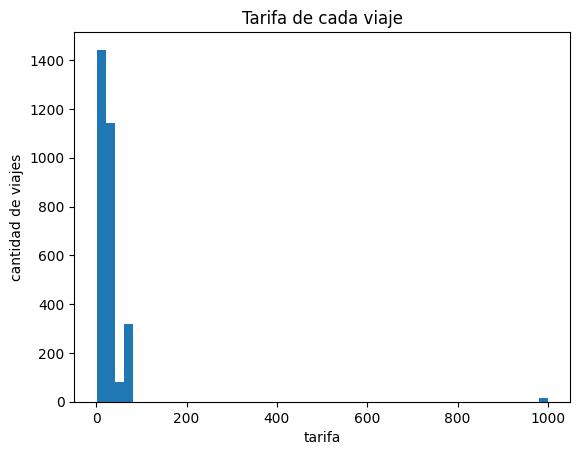

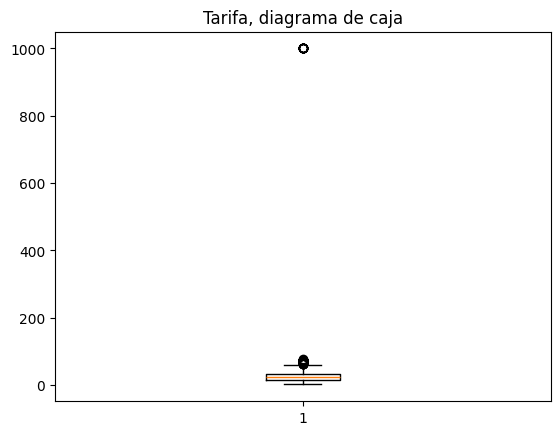

In [3]:
plt.figure()
# TODO 2: histograma de la tarifa, con 50 barras.
plt.hist(viajes["tarifa"], bins=50)
plt.title("Tarifa de cada viaje")
plt.xlabel("tarifa")
plt.ylabel("cantidad de viajes")
plt.show()

plt.figure()
plt.boxplot(viajes["tarifa"])
plt.title("Tarifa, diagrama de caja")
plt.show()

## Paso 3: atípicos con la regla del IQR

In [4]:
# TODO 3: calcula Q1, Q3, el IQR y el limite superior (Q3 + 1.5 * IQR)
# de la tarifa.
q1 = viajes["tarifa"].quantile(0.25)
q3 = viajes["tarifa"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1: {q1:.2f}  Q3: {q3:.2f}  IQR: {iqr:.2f}")
atipicos = viajes[viajes["tarifa"] > limite_superior]
print(f"Limite superior: {limite_superior:.2f}")
print(f"Viajes sobre el limite superior: {len(atipicos)}")
print(atipicos["tarifa"].value_counts().head(3))

Q1: 13.99  Q3: 32.55  IQR: 18.56
Limite superior: 60.40
Viajes sobre el limite superior: 334
tarifa
70.00     302
999.99     15
63.36       1
Name: count, dtype: int64


## Paso 4: atípico no es lo mismo que error

In [5]:
# TODO 4: de los atipicos, cuenta los que tienen la tarifa de error de
# captura (999.99) y los que tienen una tarifa exacta de 70.00.
errores_de_captura = (atipicos["tarifa"] == 999.99).sum()
tarifa_exacta_70 = (atipicos["tarifa"] == 70.00).sum()
print(f"Error de captura (999.99): {errores_de_captura}")
print(f"Tarifa exacta de 70.00: {tarifa_exacta_70}")
print(f"Duraciones negativas: {(viajes['duracion_min'] < 0).sum()}")

Error de captura (999.99): 15
Tarifa exacta de 70.00: 302
Duraciones negativas: 10
